# 01 · Data Collection: Market Stress Early-Warning System

**Research question (working):** Can signals from market networks, financial text sentiment, anomaly detection, and time-series forecasting warn of U.S. equity market stress earlier than standard financial stress indexes do?

This notebook is the first pass at the data pipeline. It:

1. Pulls benchmark stress indexes and market series from **FRED**
2. Pulls daily prices for **SPY and the nine original sector ETFs** from Yahoo Finance
3. Aligns everything on one trading-day calendar and computes log returns
4. Builds a **preliminary stress label** from the St. Louis Fed Financial Stress Index
5. Computes two first-look network-style features from the literature: rolling **average pairwise correlation** and the **absorption ratio** (Kritzman et al., 2011)
6. Saves a clean panel to `data/processed/` for the anomaly, forecasting, and network notebooks

The loading code lives in `src/data_loading.py` so the other notebooks can reuse it.

In [1]:
# Run once per environment (or: pip install -r requirements.txt)
# %pip install pandas numpy requests python-dotenv yfinance matplotlib pyarrow

In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from src import data_loading as dl

pd.set_option("display.width", 120)
START = "1999-01-01"

## 1. FRED series

If you have a free FRED API key, put it in a `.env` file in the repo root as `FRED_API_KEY=...`. Without a key the loader uses FRED's public CSV download, which works too.

| Series | What it is | Why we want it |
|---|---|---|
| `STLFSI4` | St. Louis Fed Financial Stress Index (weekly) | Candidate benchmark / label (context Q2) |
| `NFCI` | Chicago Fed National Financial Conditions Index (weekly) | Second benchmark to compare against |
| `VIXCLS` | CBOE VIX (daily) | Market-implied equity volatility |
| `BAMLH0A0HYM2` | High-yield corporate bond spread (daily) | Credit stress |
| `T10Y2Y` | 10y minus 2y Treasury spread (daily) | Yield-curve signal |

In [3]:
fred = dl.load_fred(start=START)
print(fred.shape)
fred.tail()

(7270, 5)


,STLFSI4,NFCI,VIXCLS,BAMLH0A0HYM2,T10Y2Y
date,,,,,
2026-10-22,NaN,NaN,19.03,3.40,0.31
2026-10-23,-0.5837,-0.487,19.45,3.38,0.31
2026-10-26,NaN,NaN,18.39,3.30,0.32
2026-10-27,NaN,NaN,17.52,3.18,0.29
2026-10-28,NaN,NaN,NaN,NaN,0.38


In [4]:
# Coverage check: date range, observation count, and native frequency per series
pd.DataFrame({
    "first": fred.apply(lambda s: s.first_valid_index()),
    "last": fred.apply(lambda s: s.last_valid_index()),
    "n_obs": fred.notna().sum(),
    # Typical spacing between observations: ~1 day for daily series, 7 for weekly
    "median_gap_days": fred.apply(lambda s: s.dropna().index.to_series().diff().dt.days.median()),
})

,first,last,n_obs,median_gap_days
STLFSI4,1999-01-01,2026-10-23,1452,7.0
NFCI,1999-01-01,2026-10-23,1452,7.0
VIXCLS,1999-01-04,2026-10-27,7031,1.0
BAMLH0A0HYM2,2023-10-30,2026-10-27,785,1.0
T10Y2Y,1999-01-04,2026-10-28,6960,1.0


## 2. ETF prices

SPY plus the nine original Select Sector SPDRs (XLB, XLE, XLF, XLI, XLK, XLP, XLU, XLV, XLY). XLRE and XLC are left out for now because they start in 2015 and 2018; adding them would shorten the usable history.

In [5]:
prices = dl.load_prices(start=START)
print(prices.shape)
prices.tail()

/Users/rishimaroju/Documents/RGBFS-main/.venv/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/rishimaroju/Documents/RGBFS-main/.venv/lib/python3.13/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/Users/rishimaroju/Documents/RGBFS-main/.venv/lib/python3.13/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#d

/Users/rishimaroju/Documents/RGBFS-main/.venv/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/rishimaroju/Documents/RGBFS-main/.venv/lib/python3.13/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/Users/rishimaroju/Documents/RGBFS-main/.venv/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
 

(6998, 10)


Ticker,SPY,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
date,,,,,,,,,,
2026-10-22,763.960022,51.689999,67.570000,56.650002,166.729996,182.339996,89.989998,42.869999,181.300003,115.010002
2026-10-23,759.969971,51.310001,69.330002,55.900002,164.619995,183.229996,88.260002,42.560001,179.279999,113.099998
2026-10-26,765.369995,51.380001,69.639999,56.020000,166.960007,186.320007,87.959999,42.549999,179.279999,114.260002
2026-10-27,769.659973,51.779999,68.209999,55.880001,167.919998,189.490005,87.150002,42.849998,179.179993,115.449997
2026-10-28,772.309998,51.860001,68.449997,56.130001,168.490005,191.000000,86.839996,42.490002,179.720001,115.330002


In [6]:
prices.isna().sum()

Ticker
SPY    0
XLB    0
XLE    0
XLF    0
XLI    0
XLK    0
XLP    0
XLU    0
XLV    0
XLY    0
dtype: int64

## 3. Align on trading days and add returns

Weekly indexes are forward-filled onto trading days. **Caution:** this uses the observation date, not the release date. Before we train any forecasting model, weekly series need to be shifted by their publication lag or we will leak future information (context Q6).

In [7]:
panel = dl.build_daily_panel(fred, prices)
print(panel.shape, panel.index.min().date(), "to", panel.index.max().date())
panel.filter(like="_ret").describe().T.round(4)

(6997, 25) 1999-01-05 to 2026-10-28


,count,mean,std,min,25%,50%,75%,max
SPY_ret,6997.0,0.0003,0.0121,-0.1159,-0.0047,0.0007,0.0061,0.1356
XLB_ret,6997.0,0.0003,0.0148,-0.1325,-0.0071,0.0007,0.0082,0.1315
XLE_ret,6997.0,0.0004,0.0181,-0.2249,-0.0084,0.0008,0.0098,0.1525
XLF_ret,6997.0,0.0002,0.0177,-0.1823,-0.0067,0.0006,0.0077,0.1524
XLI_ret,6997.0,0.0003,0.0133,-0.1204,-0.0057,0.0008,0.0070,0.1191
XLK_ret,6997.0,0.0004,0.0164,-0.1487,-0.0067,0.0011,0.0083,0.1493
XLP_ret,6997.0,0.0003,0.0096,-0.0987,-0.0044,0.0005,0.0053,0.0817
XLU_ret,6997.0,0.0003,0.0121,-0.1206,-0.0056,0.0009,0.0067,0.1204
XLV_ret,6997.0,0.0003,0.0112,-0.1038,-0.0051,0.0005,0.0062,0.1138
XLY_ret,6997.0,0.0004,0.0143,-0.1355,-0.0062,0.0009,0.0076,0.1034


## 4. Preliminary stress label

`STLFSI4` is built so that 0 is roughly normal conditions and positive values are above-average stress. As a **placeholder**, a day is labeled stressed when `STLFSI4 > 1`. The group still needs to decide the definition and benchmark (context Q1 to Q3).

In [8]:
panel["stress"] = dl.stress_flag(panel["STLFSI4"], threshold=1.0)
print(f"Share of trading days flagged as stressed: {panel['stress'].mean():.1%}")

# Contiguous stressed spells (start, end, length) for a quick look
spell_id = (panel["stress"].diff() != 0).cumsum()
spells = (panel[panel["stress"] == 1]
          .groupby(spell_id[panel["stress"] == 1])
          .apply(lambda g: pd.Series({"start": g.index.min().date(),
                                      "end": g.index.max().date(),
                                      "trading_days": len(g)})))
if spells.empty:
    print("No stressed days at this threshold.")
else:
    display(spells.sort_values("trading_days", ascending=False).head(10))

Share of trading days flagged as stressed: 9.0%


,start,end,trading_days
stress,,,
28,2008-06-06,2009-07-23,285
26,2008-02-08,2008-05-22,73
22,2007-11-09,2008-01-17,47
42,2020-03-06,2020-05-07,44
16,2002-09-06,2002-10-17,30
20,2007-08-17,2007-09-20,24
18,2002-10-25,2002-11-21,20
34,2011-09-23,2011-10-13,15
12,2002-07-19,2002-08-01,10


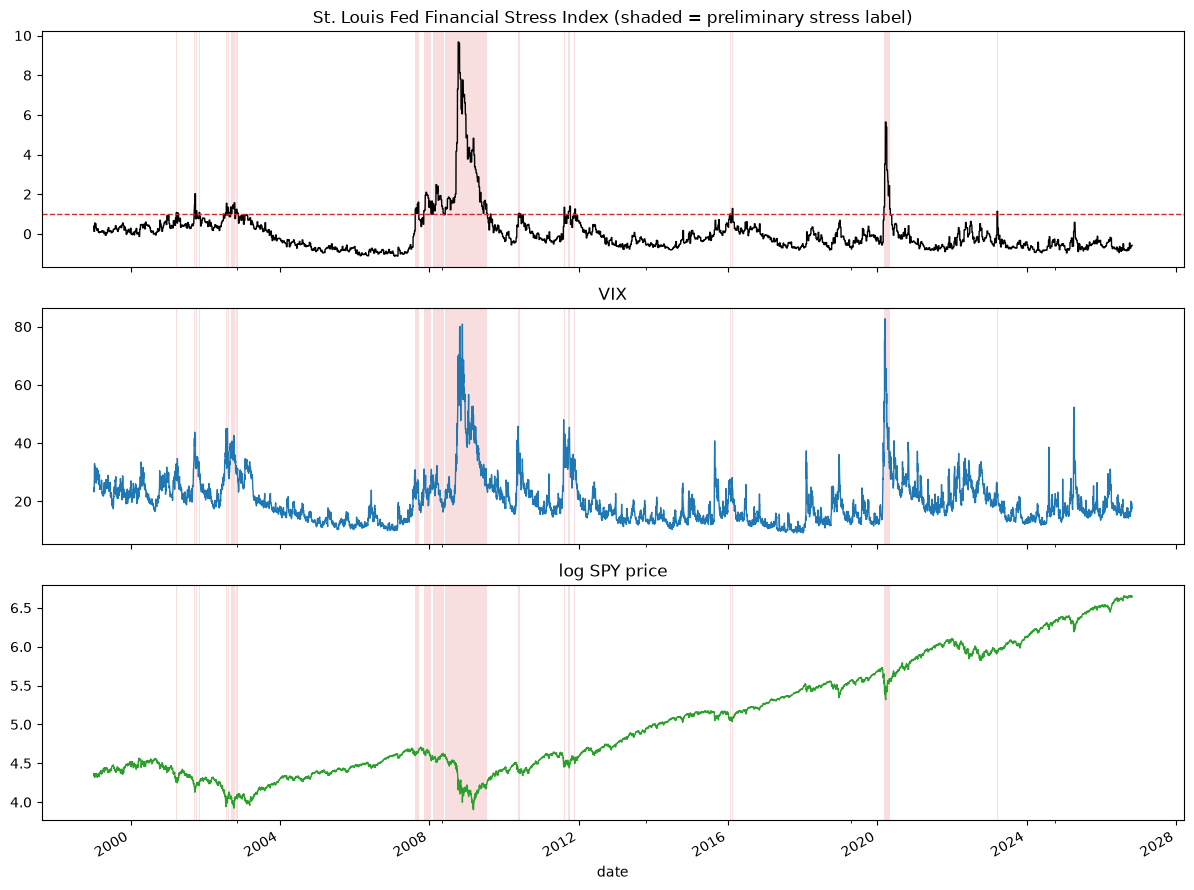

In [9]:
def shade_stress(ax, flag):
    on = flag.astype(bool)
    starts = on.index[on & ~on.shift(1, fill_value=False)]
    ends = on.index[on & ~on.shift(-1, fill_value=False)]
    for s, e in zip(starts, ends):
        ax.axvspan(s, e, color="tab:red", alpha=0.15, lw=0)

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
panel["STLFSI4"].plot(ax=axes[0], color="black", lw=1)
axes[0].axhline(1.0, ls="--", color="tab:red", lw=1)
axes[0].set_title("St. Louis Fed Financial Stress Index (shaded = preliminary stress label)")
panel["VIXCLS"].plot(ax=axes[1], color="tab:blue", lw=1); axes[1].set_title("VIX")
(np.log(panel["SPY"])).plot(ax=axes[2], color="tab:green", lw=1); axes[2].set_title("log SPY price")
for ax in axes:
    shade_stress(ax, panel["stress"])
plt.tight_layout(); plt.show()

## 5. First-look network features

Two simple measures of how tightly the sector ETFs move together:

* **Average pairwise correlation** over a 60-day window
* **Absorption ratio** (Kritzman, Li, Page & Rigobon, 2011): share of total variance explained by the top principal components over a 250-day window. This is a simplified version (plain rolling covariance instead of exponential weighting).

These feed directly into context question 4: do they rise *before* stress, or only during it?

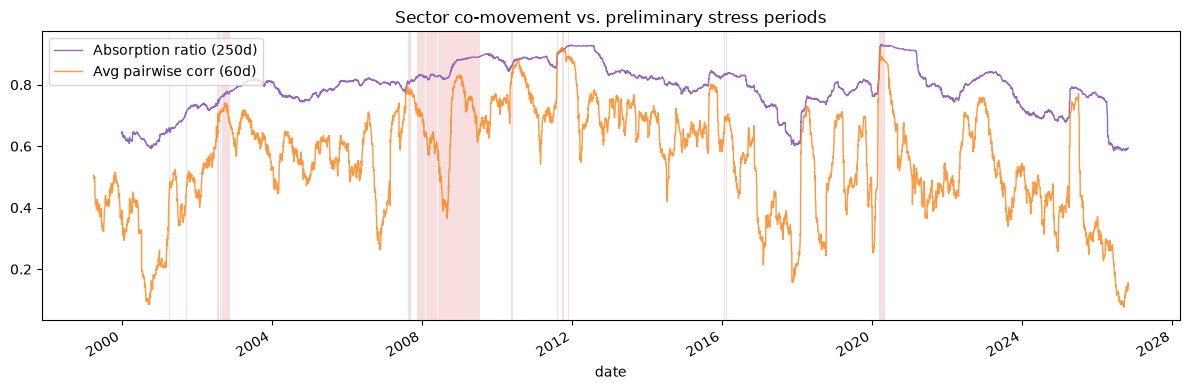

In [10]:
sector_rets = panel[[f"{t}_ret" for t in dl.SECTOR_ETFS]]
panel["avg_corr_60d"] = dl.rolling_avg_correlation(sector_rets, window=60)
panel["absorption_250d"] = dl.absorption_ratio(sector_rets, window=250)

fig, ax1 = plt.subplots(figsize=(12, 4))
panel["absorption_250d"].plot(ax=ax1, color="tab:purple", lw=1, label="Absorption ratio (250d)")
panel["avg_corr_60d"].plot(ax=ax1, color="tab:orange", lw=1, alpha=0.8, label="Avg pairwise corr (60d)")
shade_stress(ax1, panel["stress"])
ax1.legend(loc="upper left"); ax1.set_title("Sector co-movement vs. preliminary stress periods")
plt.tight_layout(); plt.show()

In [11]:
# Quick lead/lag check: correlation between each feature today and STLFSI4 h trading days later.
# Exploratory only; correlation is not a forecast test.
horizons = [0, 5, 20, 60]
rows = {}
for feat in ["avg_corr_60d", "absorption_250d", "VIXCLS", "BAMLH0A0HYM2"]:
    rows[feat] = {f"h={h}": panel[feat].corr(panel["STLFSI4"].shift(-h)) for h in horizons}
pd.DataFrame(rows).T.round(3)

,h=0,h=5,h=20,h=60
avg_corr_60d,0.315,0.301,0.239,0.100
absorption_250d,0.238,0.225,0.175,0.085
VIXCLS,0.808,0.820,0.701,0.472
BAMLH0A0HYM2,0.395,0.373,0.077,-0.293


## 6. Save the processed panel

In [12]:
dl.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
out = dl.PROCESSED_DIR / "daily_panel.parquet"
panel.to_parquet(out)
print("Saved", out.relative_to(ROOT), panel.shape)

Saved data/processed/daily_panel.parquet (6997, 28)


## Next steps

* **Decide the stress definition** (benchmark index, threshold, episode dating). Context Q1 to Q3.
* **Handle release lags** for weekly indexes before any modeling.
* **NLP data:** pick a text source (news headlines or SEC filings) and plan to score it with the Loughran–McDonald finance word lists.
* **Network component:** Diebold–Yilmaz connectedness on the sector returns.
* **Anomaly detection:** start with an Isolation Forest or rolling z-scores on returns and the features above.